# Fase C — Implementación de modelos predictivos
## Siniestralidad vial en Cali, 2016–2024
Proyecto 2 y 3 · Grupo DatosSinCiencia

### Objetivo
Entrenar y comparar tres modelos de clasificación para estimar la gravedad
registrada de los reportes viales y aplicar un modelo de agrupamiento para
identificar segmentos con características similares.

### Pregunta de negocio
¿Qué tan bien permiten las características disponibles de los reportes
clasificar su gravedad como Negativo, Solo daños, Con lesionado o Con fallecido?

### Datos de entrada
Se utiliza el archivo `datos_limpios.parquet`, generado en la Fase B.
Se conserva la partición de entrenamiento y prueba indicada en `SPLIT`,
porque la imputación y el escalado se ajustaron con ese conjunto de entrenamiento.

### Modelos
- Regresión logística.
- Árbol de decisión.
- Random Forest.
- K-Means para segmentación, sin usar la gravedad como variable de entrada.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42

df = pd.read_parquet("datos_limpios.parquet")

print(f"Dataset: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"\nValores faltantes: {df.isna().sum().sum():,}")

print("\nDistribución de gravedad:")
print(df["GRAVEDAD"].value_counts())

print("\nPartición de entrenamiento y prueba:")
print(df["SPLIT"].value_counts())

print("\nColumnas disponibles:")
print(df.columns.tolist())

df.head()

Dataset: 370,996 filas × 39 columnas

Valores faltantes: 0

Distribución de gravedad:
GRAVEDAD
Negativo         246107
Solo daños        74029
Con lesionado     47500
Con fallecido      3360
Name: count, dtype: int64

Partición de entrenamiento y prueba:
SPLIT
train    296796
test      74200
Name: count, dtype: int64

Columnas disponibles:
['CODIGO', 'FECHA', 'SPLIT', 'GRAVEDAD', 'GRAVEDAD_NUM', 'YJ_NUM_VEHICULOS', 'YJ_N_MOTOS', 'N_AUTOS', 'YJ_N_PUBLICO', 'YJ_N_CARGA', 'YJ_N_BICIS', 'YJ_N_OTROS', 'ANIO', 'MES', 'PERIODO_NUM', 'SIN_DATO_VEHICULOS', 'CLASE_ACCIDENTE_CHOQUE', 'CLASE_ACCIDENTE_ATROPELLO', 'CLASE_ACCIDENTE_VOLCAMIENTO', 'CLASE_ACCIDENTE_CAIDA_DE_OCUPANTE', 'CLASE_ACCIDENTE_OTRO', 'CLASE_ACCIDENTE_NO_APLICA', 'MEDIO_REPORTE_LINEA_127', 'MEDIO_REPORTE_CAD_123', 'MEDIO_REPORTE_RADIO', 'MEDIO_REPORTE_OTRO', 'TIPO_VIA_CALLE', 'TIPO_VIA_CARRERA', 'TIPO_VIA_AVENIDA', 'TIPO_VIA_DIAGONAL_TRANSVERSAL', 'TIPO_VIA_VIA_CARRETERA', 'TIPO_VIA_CENTRO_MEDICO', 'TIPO_VIA_OTRO_LUGAR', 'DIA_SE

,CODIGO,FECHA,SPLIT,GRAVEDAD,GRAVEDAD_NUM,YJ_NUM_VEHICULOS,YJ_N_MOTOS,N_AUTOS,YJ_N_PUBLICO,YJ_N_CARGA,...,TIPO_VIA_DIAGONAL_TRANSVERSAL,TIPO_VIA_VIA_CARRETERA,TIPO_VIA_CENTRO_MEDICO,TIPO_VIA_OTRO_LUGAR,DIA_SEMANA_MARTES,DIA_SEMANA_MIERCOLES,DIA_SEMANA_JUEVES,DIA_SEMANA_VIERNES,DIA_SEMANA_SABADO,DIA_SEMANA_DOMINGO
0,96159,2016-01-01,test,Solo daños,1,0.082791,2.104897,-2.112221,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
1,96160,2016-01-01,train,Negativo,0,0.082791,-0.474507,-0.125850,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
2,96161,2016-01-01,train,Con lesionado,2,0.082791,2.104897,-2.112221,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
3,96162,2016-01-01,train,Con lesionado,2,-3.333620,2.104897,-2.112221,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0
4,96163,2016-01-01,train,Negativo,0,0.082791,-0.474507,-0.125850,-0.193859,-0.170571,...,0,0,0,0,0,0,0,1,0,0


In [2]:
print("Cantidad y porcentaje de reportes por gravedad:")
resumen_clases = pd.DataFrame({
    "reportes": df["GRAVEDAD"].value_counts(),
    "porcentaje": df["GRAVEDAD"].value_counts(normalize=True).mul(100).round(2)
})
display(resumen_clases)

print("\nDistribución de clases en entrenamiento y prueba:")
display(pd.crosstab(df["GRAVEDAD"], df["SPLIT"]))

print("\nColumnas disponibles:")
for columna in df.columns:
    print(columna)

print(f"\nValores faltantes: {df.isna().sum().sum()}")
print(f"Códigos repetidos: {df['CODIGO'].duplicated().sum()}")

Cantidad y porcentaje de reportes por gravedad:


,reportes,porcentaje
GRAVEDAD,,
Negativo,246107,66.34
Solo daños,74029,19.95
Con lesionado,47500,12.80
Con fallecido,3360,0.91



Distribución de clases en entrenamiento y prueba:


SPLIT,test,train
GRAVEDAD,,
Con fallecido,672,2688
Con lesionado,9500,38000
Negativo,49222,196885
Solo daños,14806,59223



Columnas disponibles:
CODIGO
FECHA
SPLIT
GRAVEDAD
GRAVEDAD_NUM
YJ_NUM_VEHICULOS
YJ_N_MOTOS
N_AUTOS
YJ_N_PUBLICO
YJ_N_CARGA
YJ_N_BICIS
YJ_N_OTROS
ANIO
MES
PERIODO_NUM
SIN_DATO_VEHICULOS
CLASE_ACCIDENTE_CHOQUE
CLASE_ACCIDENTE_ATROPELLO
CLASE_ACCIDENTE_VOLCAMIENTO
CLASE_ACCIDENTE_CAIDA_DE_OCUPANTE
CLASE_ACCIDENTE_OTRO
CLASE_ACCIDENTE_NO_APLICA
MEDIO_REPORTE_LINEA_127
MEDIO_REPORTE_CAD_123
MEDIO_REPORTE_RADIO
MEDIO_REPORTE_OTRO
TIPO_VIA_CALLE
TIPO_VIA_CARRERA
TIPO_VIA_AVENIDA
TIPO_VIA_DIAGONAL_TRANSVERSAL
TIPO_VIA_VIA_CARRETERA
TIPO_VIA_CENTRO_MEDICO
TIPO_VIA_OTRO_LUGAR
DIA_SEMANA_MARTES
DIA_SEMANA_MIERCOLES
DIA_SEMANA_JUEVES
DIA_SEMANA_VIERNES
DIA_SEMANA_SABADO
DIA_SEMANA_DOMINGO

Valores faltantes: 0
Códigos repetidos: 0


In [3]:
orden_gravedad = [
    "Negativo",
    "Solo daños",
    "Con lesionado",
    "Con fallecido"
]

tabla_clases = pd.crosstab(
    df["GRAVEDAD"],
    df["SPLIT"]
).reindex(orden_gravedad)

tabla_clases["total"] = tabla_clases.sum(axis=1)
tabla_clases["porcentaje"] = (
    tabla_clases["total"] / len(df) * 100
).round(2)

print(tabla_clases.to_string())

SPLIT           test   train   total  porcentaje
GRAVEDAD                                        
Negativo       49222  196885  246107       66.34
Solo daños     14806   59223   74029       19.95
Con lesionado   9500   38000   47500       12.80
Con fallecido    672    2688    3360        0.91


## 1. Preparación de los datos para clasificación

La variable objetivo es GRAVEDAD, con cuatro categorías. Se conserva la
partición 80/20 generada con train_test_split en la Fase B, porque las
imputaciones y los escaladores se ajustaron con ese conjunto de entrenamiento.

Las clases están desbalanceadas: Negativo representa el 66,34 % y
Con fallecido el 0,91 %. Se reportarán Accuracy, Precision, Recall y F1,
incluyendo F1 macro y resultados por clase para no ocultar el desempeño
en las categorías minoritarias.

Se excluyen los identificadores y las dos representaciones del objetivo.
También se excluyen la clase de accidente, el tipo de vía y el indicador
de vehículos faltantes, por su posible relación con la confirmación y
el registro del resultado.

El análisis clasifica reportes históricos con las características disponibles.
No demuestra capacidad para anticipar accidentes ni su gravedad antes de ocurrir.

In [4]:
columnas_excluir = [
    "CODIGO", "FECHA", "SPLIT", "GRAVEDAD", "GRAVEDAD_NUM",
    "SIN_DATO_VEHICULOS"
]

columnas_predictoras = [
    columna for columna in df.columns
    if columna not in columnas_excluir
    and not columna.startswith("CLASE_ACCIDENTE_")
    and not columna.startswith("TIPO_VIA_")
]

train = df[df["SPLIT"] == "train"].copy()
test = df[df["SPLIT"] == "test"].copy()

X_train = train[columnas_predictoras]
X_test = test[columnas_predictoras]
y_train = train["GRAVEDAD"]
y_test = test["GRAVEDAD"]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("\nVariables predictoras:")
print("\n".join(columnas_predictoras))

Entrenamiento: (296796, 20)
Prueba: (74200, 20)

Variables predictoras:
YJ_NUM_VEHICULOS
YJ_N_MOTOS
N_AUTOS
YJ_N_PUBLICO
YJ_N_CARGA
YJ_N_BICIS
YJ_N_OTROS
ANIO
MES
PERIODO_NUM
MEDIO_REPORTE_LINEA_127
MEDIO_REPORTE_CAD_123
MEDIO_REPORTE_RADIO
MEDIO_REPORTE_OTRO
DIA_SEMANA_MARTES
DIA_SEMANA_MIERCOLES
DIA_SEMANA_JUEVES
DIA_SEMANA_VIERNES
DIA_SEMANA_SABADO
DIA_SEMANA_DOMINGO


## 2. Modelo 1 — Regresión logística

La regresión logística permite clasificar los reportes en las cuatro
categorías de gravedad. Se utiliza como primer modelo por su simplicidad
y para compararla después con el árbol de decisión y Random Forest.

Se usa class_weight="balanced" para dar mayor peso durante el entrenamiento
a las clases menos frecuentes. El conjunto de prueba conserva su distribución
original y no participa en el entrenamiento.

Accuracy: 0.7243

Resultados por clase:
               precision    recall  f1-score   support

     Negativo     0.8922    0.8057    0.8467     49222
   Solo daños     0.6200    0.5983    0.6089     14806
Con lesionado     0.4327    0.5052    0.4661      9500
Con fallecido     0.0981    0.6384    0.1701       672

     accuracy                         0.7243     74200
    macro avg     0.5107    0.6369    0.5230     74200
 weighted avg     0.7718    0.7243    0.7444     74200



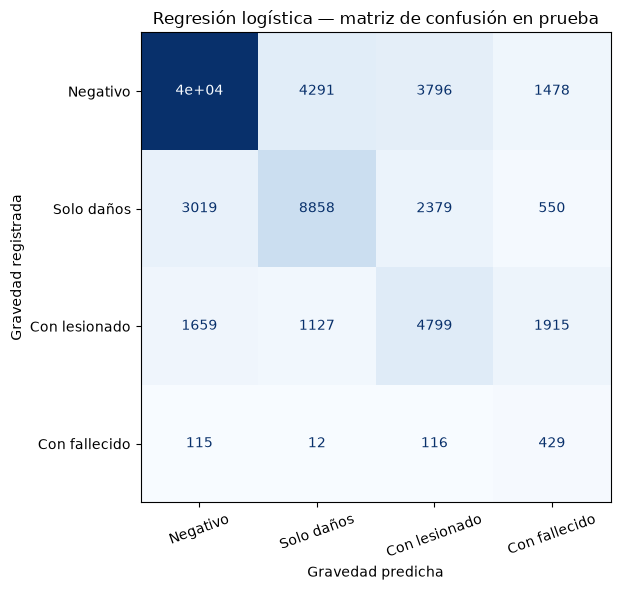

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

modelo_logistica = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEMILLA
)

modelo_logistica.fit(X_train, y_train)
pred_logistica = modelo_logistica.predict(X_test)

# Evaluamos únicamente las filas reservadas para prueba.
print("Accuracy:", round(accuracy_score(y_test, pred_logistica), 4))
print("\nResultados por clase:")
print(classification_report(
    y_test,
    pred_logistica,
    labels=orden_gravedad,
    digits=4,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(9, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_logistica,
    labels=orden_gravedad,
    display_labels=orden_gravedad,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Regresión logística — matriz de confusión en prueba")
ax.set_xlabel("Gravedad predicha")
ax.set_ylabel("Gravedad registrada")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretación:** La regresión logística alcanza un Accuracy del 72,43 %
y un F1 macro de 0,5230. El desempeño varía entre categorías: el F1 es
0,8467 para Negativo y 0,1701 para Con fallecido, por lo que el acierto
global no representa igual de bien a todas las clases.

**Insight:** El modelo identifica 429 de los 672 reportes con fallecidos
(Recall del 63,84 %), pero solo el 9,81 % de sus predicciones de esta
categoría es correcto. Esto implica numerosas falsas alarmas y limita
su utilidad para priorizar revisiones con recursos escasos; compararemos
este resultado con los otros modelos antes de elegir uno.

In [6]:
resultados = []

resultados.append({
    "Modelo": "Regresión logística",
    "Accuracy": accuracy_score(y_test, pred_logistica),
    "Precision macro": precision_score(
        y_test, pred_logistica, average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_test, pred_logistica, average="macro", zero_division=0
    ),
    "F1 macro": f1_score(
        y_test, pred_logistica, average="macro", zero_division=0
    ),
    "F1 weighted": f1_score(
        y_test, pred_logistica, average="weighted", zero_division=0
    )
})

display(pd.DataFrame(resultados).round(4))

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Regresión logística,0.7243,0.5107,0.6369,0.523,0.7444


## 3. Modelo 2 — Árbol de decisión

El árbol de decisión aprende reglas que dividen los reportes según sus
características. A diferencia de la regresión logística, puede representar
relaciones no lineales e interacciones entre variables.

Se limita la profundidad a 8 para controlar la complejidad, siguiendo el
ejemplo de clase. Se mantiene class_weight="balanced" para dar mayor peso
a las clases minoritarias. Estos parámetros se fijan antes de evaluar;
el conjunto de prueba no se utiliza para ajustarlos.

Resultados por clase:
               precision    recall  f1-score   support

     Negativo     0.8948    0.8078    0.8491     49222
   Solo daños     0.6443    0.5622    0.6004     14806
Con lesionado     0.4214    0.5729    0.4856      9500
Con fallecido     0.1051    0.6146    0.1795       672

     accuracy                         0.7270     74200
    macro avg     0.5164    0.6394    0.5287     74200
 weighted avg     0.7771    0.7270    0.7469     74200



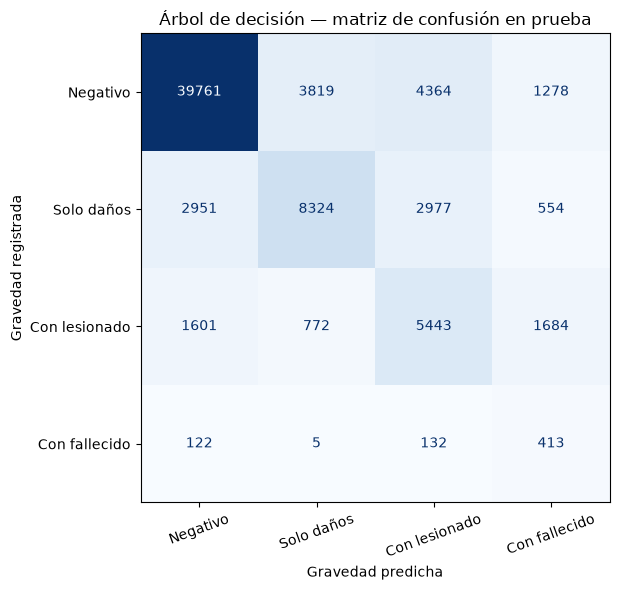

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Regresión logística,0.7243,0.5107,0.6369,0.5230,0.7444
1,Árbol de decisión,0.7270,0.5164,0.6394,0.5287,0.7469


In [7]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol = DecisionTreeClassifier(
    max_depth=8,
    class_weight="balanced",
    random_state=SEMILLA
)

modelo_arbol.fit(X_train, y_train)
pred_arbol = modelo_arbol.predict(X_test)

print("Resultados por clase:")
print(classification_report(
    y_test,
    pred_arbol,
    labels=orden_gravedad,
    digits=4,
    zero_division=0
))

# Conservamos las mismas métricas y el mismo conjunto de prueba.
metricas_arbol = {
    "Modelo": "Árbol de decisión",
    "Accuracy": accuracy_score(y_test, pred_arbol),
    "Precision macro": precision_score(
        y_test, pred_arbol, average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_test, pred_arbol, average="macro", zero_division=0
    ),
    "F1 macro": f1_score(
        y_test, pred_arbol, average="macro", zero_division=0
    ),
    "F1 weighted": f1_score(
        y_test, pred_arbol, average="weighted", zero_division=0
    )
}

resultados = [
    fila for fila in resultados
    if fila["Modelo"] != "Árbol de decisión"
]
resultados.append(metricas_arbol)

fig, ax = plt.subplots(figsize=(9, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_arbol,
    labels=orden_gravedad,
    display_labels=orden_gravedad,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Árbol de decisión — matriz de confusión en prueba")
ax.set_xlabel("Gravedad predicha")
ax.set_ylabel("Gravedad registrada")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(pd.DataFrame(resultados).round(4))

**Interpretación:** El árbol de decisión obtiene un Accuracy del 72,70 %
y un F1 macro de 0,5287, frente al 72,43 % y 0,5230 de la regresión
logística. La mejora global es pequeña y varía según la categoría:
el F1 aumenta para Negativo, Con lesionado y Con fallecido, pero
disminuye para Solo daños, de 0,6089 a 0,6004.

**Insight:** El árbol identifica 413 de los 672 reportes con fallecidos
(Recall del 61,46 %), frente a los 429 identificados por la regresión
logística. Su precisión para esta clase mejora del 9,81 % al 10,51 %:
reduce las falsas alarmas de 3.943 a 3.516, aunque deja sin identificar
16 casos adicionales con fallecidos.

**Implicación de negocio:** Para los reportes con lesionados, el Recall
aumenta del 50,52 % al 57,29 %, pero para los reportes con fallecidos
disminuye. Por tanto, la elección depende de qué errores se consideren
más costosos; el árbol todavía produce numerosas falsas alarmas y su
ligera ventaja global no basta para declararlo el modelo final.

## 4. Modelo 3 — Random Forest

Random Forest combina varios árboles entrenados con muestras aleatorias
de los datos y subconjuntos de variables. Como se explicó en clase,
esta diversidad puede reducir el sobreajuste de un árbol individual.

Se utilizan 200 árboles con profundidad máxima de 8, siguiendo el
ejemplo de la preclase de ensambles. Se mantiene la ponderación de clases
y se evalúa sobre el mismo conjunto de prueba de los modelos anteriores.

Resultados por clase:
               precision    recall  f1-score   support

     Negativo     0.8912    0.8024    0.8445     49222
   Solo daños     0.6471    0.5661    0.6039     14806
Con lesionado     0.4311    0.5828    0.4956      9500
Con fallecido     0.1032    0.6280    0.1773       672

     accuracy                         0.7256     74200
    macro avg     0.5182    0.6448    0.5303     74200
 weighted avg     0.7765    0.7256    0.7458     74200



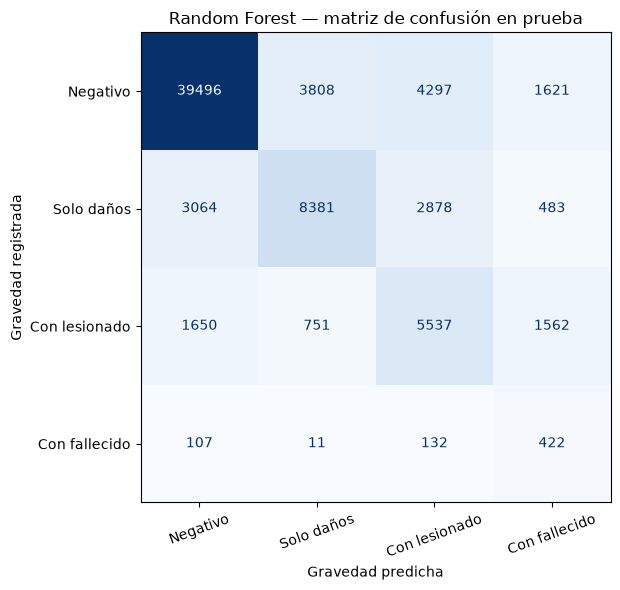

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Regresión logística,0.7243,0.5107,0.6369,0.5230,0.7444
1,Árbol de decisión,0.7270,0.5164,0.6394,0.5287,0.7469
2,Random Forest,0.7256,0.5182,0.6448,0.5303,0.7458


In [8]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight="balanced",
    random_state=SEMILLA,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)
pred_rf = modelo_rf.predict(X_test)

print("Resultados por clase:")
print(classification_report(
    y_test,
    pred_rf,
    labels=orden_gravedad,
    digits=4,
    zero_division=0
))

# Evaluamos con las mismas métricas usadas para los otros modelos.
metricas_rf = {
    "Modelo": "Random Forest",
    "Accuracy": accuracy_score(y_test, pred_rf),
    "Precision macro": precision_score(
        y_test, pred_rf, average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_test, pred_rf, average="macro", zero_division=0
    ),
    "F1 macro": f1_score(
        y_test, pred_rf, average="macro", zero_division=0
    ),
    "F1 weighted": f1_score(
        y_test, pred_rf, average="weighted", zero_division=0
    )
}

resultados = [
    fila for fila in resultados
    if fila["Modelo"] != "Random Forest"
]
resultados.append(metricas_rf)

fig, ax = plt.subplots(figsize=(9, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_rf,
    labels=orden_gravedad,
    display_labels=orden_gravedad,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Random Forest — matriz de confusión en prueba")
ax.set_xlabel("Gravedad predicha")
ax.set_ylabel("Gravedad registrada")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(pd.DataFrame(resultados).round(4))

**Interpretación:** Random Forest alcanza un Accuracy del 72,56 % y
un F1 macro de 0,5303, el mayor de los tres modelos evaluados. Su ventaja
en F1 macro frente al árbol es de solo 0,0016; estos resultados no
demuestran una superioridad amplia ni consistente en todas las clases.

**Insight:** Identifica 422 de los 672 reportes con fallecidos
(Recall del 62,80 %), pero genera 3.666 falsas alarmas para esa
categoría. Su precisión del 10,32 % significa que aproximadamente
una de cada diez predicciones de fallecidos es correcta; además,
250 reportes con fallecidos se clasifican en otras categorías.

**Comparación:** Random Forest obtiene el mayor F1 para Con lesionado
(0,4956), mientras que el árbol consigue el mayor F1 para Con fallecido
(0,1795) y el mayor Accuracy global. La regresión logística conserva
el mayor Recall para fallecidos (63,84 %). Ningún modelo domina
en todos los criterios.

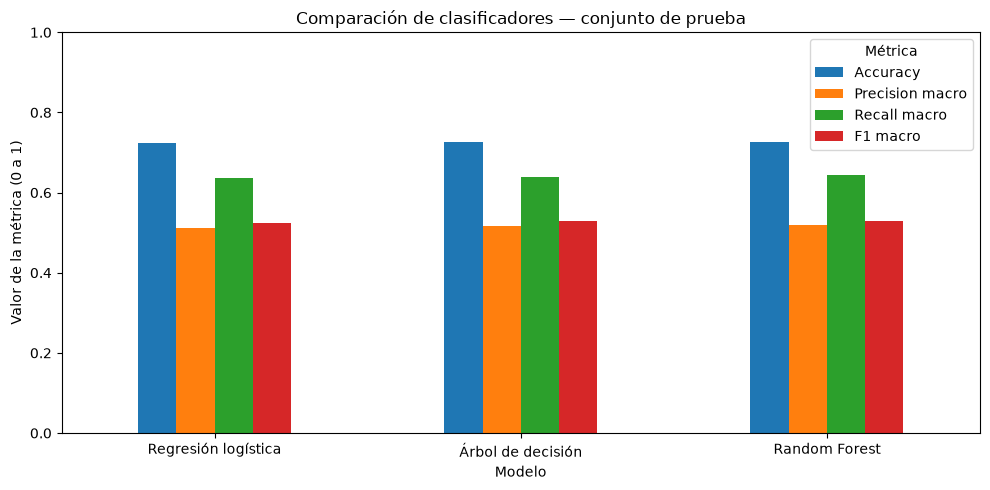

,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
Modelo,,,,,
Regresión logística,0.7243,0.5107,0.6369,0.5230,0.7444
Árbol de decisión,0.7270,0.5164,0.6394,0.5287,0.7469
Random Forest,0.7256,0.5182,0.6448,0.5303,0.7458


In [9]:
tabla_comparativa = pd.DataFrame(resultados).set_index("Modelo")

fig, ax = plt.subplots(figsize=(10, 5))

tabla_comparativa[
    ["Accuracy", "Precision macro", "Recall macro", "F1 macro"]
].plot.bar(ax=ax)

ax.set_title("Comparación de clasificadores — conjunto de prueba")
ax.set_xlabel("Modelo")
ax.set_ylabel("Valor de la métrica (0 a 1)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Métrica", loc="upper right")

plt.tight_layout()
plt.show()

display(tabla_comparativa.round(4))

**Insight:** Los tres modelos presentan resultados globales cercanos:
el Accuracy está entre 72,43 % y 72,70 %, y el F1 macro entre
0,5230 y 0,5303. La diferencia entre Accuracy y F1 macro muestra
por qué es necesario examinar cada clase en este dataset desbalanceado.

**Criterio de selección:** Se utiliza F1 macro como criterio principal
porque asigna el mismo peso a cada categoría y combina Precision
y Recall. Con este criterio, Random Forest es el candidato final
entre las configuraciones evaluadas, aunque su ventaja es pequeña
y su baja precisión para fallecidos limita su utilidad práctica.

**Limitación de la evaluación:** Los resultados corresponden a una
única partición aleatoria de reportes históricos. No garantizan
el mismo desempeño en años futuros ni justifican decisiones
automáticas sobre casos individuales.

## 5. Modelo no supervisado — K-Means

K-Means agrupa reportes con características similares sin utilizar la
gravedad como entrada. Se emplean las mismas 20 variables predictoras,
que ya fueron transformadas y escaladas en la Fase B.

Se comparan entre 2 y 10 grupos mediante Silhouette y Davies-Bouldin.
Un Silhouette más alto indica grupos más separados y cohesionados;
un Davies-Bouldin más bajo indica una mejor separación relativa.

Para limitar el tiempo de cálculo, esta exploración utiliza una muestra
reproducible de 10.000 reportes de entrenamiento. Silhouette se calcula
sobre 2.000 de ellos. La elección de K se realiza sin consultar el
conjunto de prueba ni las etiquetas de gravedad.

Los segmentos pueden reflejar tanto características de los reportes
como diferencias en la captura de información entre periodos.
No se interpretarán automáticamente como niveles de riesgo vial.

,Silhouette,Davies-Bouldin,Inercia
K,,,
2,0.3532,1.4542,72328.6466
3,0.3642,1.0238,61669.9330
4,0.3752,0.7997,50921.7467
5,0.4105,0.7333,40358.9192
6,0.4334,0.6672,31455.8792
7,0.3943,0.7511,25975.5745
8,0.4243,0.7332,21770.0677
9,0.2694,1.0229,20586.7689
10,0.3172,0.9796,18228.1955


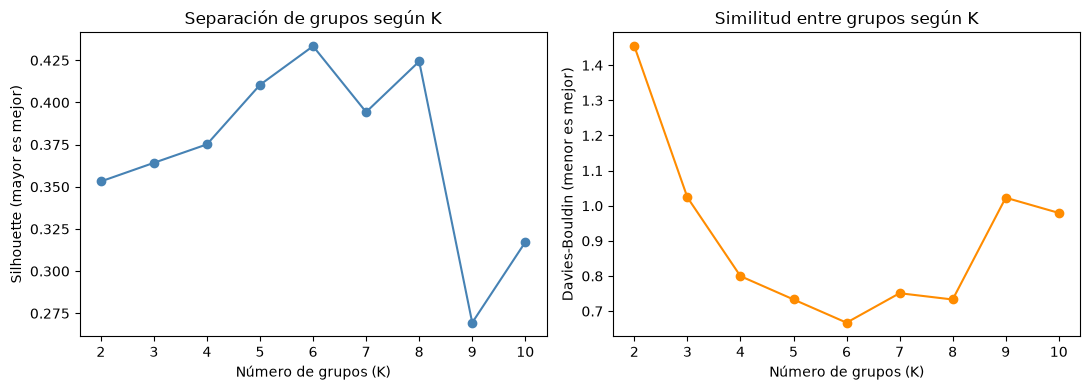

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

muestra_clustering = X_train.sample(
    n=min(10000, len(X_train)),
    random_state=SEMILLA
)

resultados_k = []

for k in range(2, 11):
    modelo_k = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEMILLA
    )
    etiquetas_k = modelo_k.fit_predict(muestra_clustering)

    # Comparamos K usando únicamente reportes de entrenamiento.
    silhouette = silhouette_score(
        muestra_clustering,
        etiquetas_k,
        sample_size=2000,
        random_state=SEMILLA
    )
    davies = davies_bouldin_score(
        muestra_clustering,
        etiquetas_k
    )

    resultados_k.append({
        "K": k,
        "Silhouette": silhouette,
        "Davies-Bouldin": davies,
        "Inercia": modelo_k.inertia_
    })

tabla_k = pd.DataFrame(resultados_k).set_index("K")
display(tabla_k.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

tabla_k["Silhouette"].plot(
    marker="o", ax=axes[0], color="steelblue"
)
axes[0].set_title("Separación de grupos según K")
axes[0].set_xlabel("Número de grupos (K)")
axes[0].set_ylabel("Silhouette (mayor es mejor)")

tabla_k["Davies-Bouldin"].plot(
    marker="o", ax=axes[1], color="darkorange"
)
axes[1].set_title("Similitud entre grupos según K")
axes[1].set_xlabel("Número de grupos (K)")
axes[1].set_ylabel("Davies-Bouldin (menor es mejor)")

for ax in axes:
    ax.set_xticks(tabla_k.index)

plt.tight_layout()
plt.show()

**Insight:** K = 6 presenta el mayor Silhouette (0,4334) y el menor
Davies-Bouldin (0,6672) entre las alternativas de 2 a 10 grupos.
Ambos criterios coinciden en favorecer esta configuración sobre
la muestra de entrenamiento utilizada.

Se seleccionan seis segmentos para el modelo final. Esta elección
corresponde al rango, la muestra y las variables evaluadas; no demuestra
que existan exactamente seis grupos naturales en todos los reportes.

### 5.1 Entrenamiento y evaluación del agrupamiento final

Se ajusta K-Means con seis grupos sobre todo el conjunto de entrenamiento.
Después se asignan los reportes de prueba a los centros aprendidos.

Silhouette y Davies-Bouldin se calculan sobre una muestra reproducible
de prueba para limitar el costo de cálculo. Estas métricas describen
la estructura de los grupos; no miden aciertos al predecir gravedad.

In [11]:
modelo_kmeans = KMeans(
    n_clusters=6,
    n_init=10,
    random_state=SEMILLA
)

modelo_kmeans.fit(X_train)

clusters_train = modelo_kmeans.labels_
clusters_test = modelo_kmeans.predict(X_test)

# Evaluamos la separación en una muestra de prueba sin reajustar centros.
muestra_test = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=SEMILLA
)
clusters_muestra = modelo_kmeans.predict(muestra_test)

print("Grupos presentes en la muestra de prueba:")
print(pd.Series(clusters_muestra).value_counts().sort_index())

if 1 < len(np.unique(clusters_muestra)) < len(muestra_test):
    metricas_clustering = pd.DataFrame([{
        "Modelo": "K-Means",
        "K": 6,
        "Reportes evaluados": len(muestra_test),
        "Silhouette": silhouette_score(
            muestra_test, clusters_muestra
        ),
        "Davies-Bouldin": davies_bouldin_score(
            muestra_test, clusters_muestra
        )
    }])
    display(metricas_clustering.round(4))
else:
    print("No hay suficientes grupos para calcular las métricas.")

# Comparamos el tamaño de los segmentos en entrenamiento y prueba.
tamanos_clusters = pd.DataFrame({
    "Train": pd.Series(clusters_train).value_counts(),
    "Test": pd.Series(clusters_test).value_counts()
}).fillna(0).astype(int).sort_index()

tamanos_clusters.index.name = "Cluster"
display(tamanos_clusters)

Grupos presentes en la muestra de prueba:
0    1531
1       6
2      69
3      41
4     350
5       3
Name: count, dtype: int64


,Modelo,K,Reportes evaluados,Silhouette,Davies-Bouldin
0,K-Means,6,2000,0.4261,0.6779


,Train,Test
Cluster,,
0,225919,56486
1,1050,251
2,10155,2526
3,8330,2078
4,50543,12660
5,799,199


**Interpretación:** K-Means obtiene un Silhouette de 0,4261 y un
Davies-Bouldin de 0,6779 sobre 2.000 reportes de prueba. Los valores
son cercanos a los de la exploración, aunque no son directamente
equivalentes: el modelo final se entrenó con todas las filas de
entrenamiento y se evaluó sobre otra muestra.

**Insight:** Los segmentos tienen tamaños muy diferentes. El grupo 0
concentra aproximadamente el 76 % de los reportes tanto en entrenamiento
como en prueba, mientras que los grupos 1 y 5 son poco frecuentes.
La muestra de evaluación contiene solo seis y tres reportes de estos
dos grupos, respectivamente, por lo que las métricas globales ofrecen
información limitada sobre su comportamiento.

Los números de cluster son identificadores, no niveles de gravedad.
Es necesario examinar sus características antes de asignarles un
significado de negocio.

,YJ_NUM_VEHICULOS,YJ_N_MOTOS,N_AUTOS,YJ_N_PUBLICO,YJ_N_CARGA,YJ_N_BICIS,YJ_N_OTROS
CLUSTER,,,,,,,
0,0.036,-0.472,0.246,-0.194,-0.171,-0.060,-0.052
1,0.125,0.538,-1.198,0.306,0.002,16.743,-0.052
2,-0.122,-0.001,-0.941,5.158,-0.171,-0.060,-0.052
3,0.226,-0.056,-0.654,0.097,5.863,-0.060,-0.052
4,-0.179,2.108,-0.764,-0.194,-0.171,-0.060,-0.052
5,0.228,0.120,-0.849,0.101,0.064,0.045,19.247


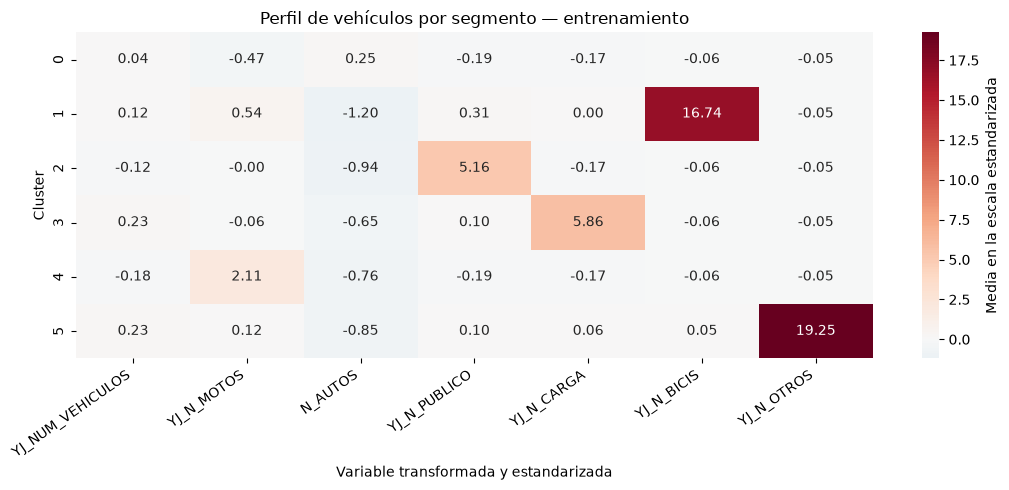

Características temporales y canales de reporte:


,ANIO,MES,PERIODO_NUM,MEDIO_REPORTE_LINEA_127,MEDIO_REPORTE_CAD_123,MEDIO_REPORTE_RADIO,MEDIO_REPORTE_OTRO,DIA_SEMANA_MARTES,DIA_SEMANA_MIERCOLES,DIA_SEMANA_JUEVES,DIA_SEMANA_VIERNES,DIA_SEMANA_SABADO,DIA_SEMANA_DOMINGO
CLUSTER,,,,,,,,,,,,,
0,0.344,0.502,0.199,0.093,0.062,0.062,0.001,0.150,0.147,0.148,0.158,0.152,0.108
1,0.491,0.501,0.353,0.108,0.076,0.123,0.002,0.184,0.147,0.136,0.153,0.141,0.099
2,0.395,0.520,0.232,0.087,0.056,0.090,0.001,0.169,0.162,0.154,0.158,0.126,0.072
3,0.405,0.516,0.244,0.097,0.053,0.085,0.002,0.173,0.174,0.164,0.169,0.139,0.031
4,0.398,0.510,0.249,0.085,0.072,0.082,0.001,0.151,0.147,0.148,0.153,0.142,0.117
5,0.406,0.516,0.252,0.068,0.070,0.103,0.001,0.171,0.134,0.143,0.174,0.146,0.096


In [12]:
perfil_train = X_train.copy()
perfil_train["CLUSTER"] = clusters_train

# Las medias conservan la escala preparada en la Fase B.
medias_clusters = perfil_train.groupby("CLUSTER").mean()

columnas_vehiculos = [
    "YJ_NUM_VEHICULOS", "YJ_N_MOTOS", "N_AUTOS",
    "YJ_N_PUBLICO", "YJ_N_CARGA", "YJ_N_BICIS", "YJ_N_OTROS"
]

display(medias_clusters[columnas_vehiculos].round(3))

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(
    medias_clusters[columnas_vehiculos],
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    ax=ax,
    cbar_kws={"label": "Media en la escala estandarizada"}
)
ax.set_title("Perfil de vehículos por segmento — entrenamiento")
ax.set_xlabel("Variable transformada y estandarizada")
ax.set_ylabel("Cluster")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Características temporales y canales de reporte:")
columnas_contexto = [
    columna for columna in columnas_predictoras
    if columna not in columnas_vehiculos
]
display(medias_clusters[columnas_contexto].round(3))

**Insight:** Los seis segmentos se diferencian principalmente por sus
perfiles de vehículos. El grupo 4 destaca en motocicletas, el 2 en
transporte público, el 3 en carga, el 1 en bicicletas y el 5 en otros
vehículos. El grupo 0 presenta una media de automóviles superior a la
media de entrenamiento y valores inferiores en los demás grupos de vehículos.

| Cluster | Descripción según las variables analizadas |
|---|---|
| 0 | Perfil mayoritario con mayor valor relativo de automóviles. |
| 1 | Perfil destacado en bicicletas. |
| 2 | Perfil destacado en transporte público. |
| 3 | Perfil destacado en vehículos de carga. |
| 4 | Perfil destacado en motocicletas. |
| 5 | Perfil destacado en otros vehículos. |

**Limitación:** Las medias corresponden a variables transformadas,
imputadas y estandarizadas, no a cantidades originales de vehículos.
El grupo 0 puede mezclar reportes con automóviles y reportes con valores
imputados; por tanto, no se interpreta como un segmento exclusivo de
automóviles. Asimismo, los valores estandarizados elevados en bicicletas
y otros vehículos reflejan características poco frecuentes y no indican
por sí solos errores de captura ni mayor gravedad.

**Implicación de negocio:** La segmentación permite organizar la revisión
de reportes por perfiles de actores viales. No demuestra diferencias
de riesgo o gravedad entre segmentos, ni permite interpretar los números
de cluster como una jerarquía.

### 5.2 Visualización de los segmentos con PCA

Se ajusta PCA únicamente con entrenamiento y se proyecta una muestra
de prueba sobre dos componentes principales. Los colores representan
los segmentos asignados por K-Means en las 20 variables originales
del modelado; PCA se utiliza solo para visualizarlos.

La proyección conserva únicamente parte de la variabilidad. Por ello,
un solapamiento en el gráfico no implica que los grupos sean idénticos
en el espacio completo.

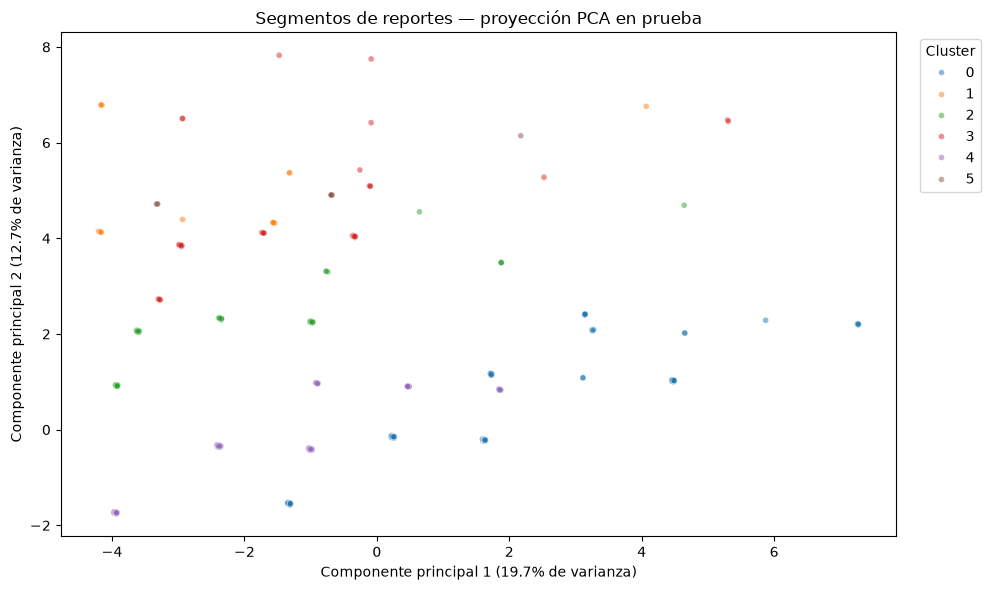

Varianza explicada por los dos componentes: 32.35%


In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(X_train)

muestra_pca = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=SEMILLA
)

coordenadas = pca.transform(muestra_pca)

grafico_pca = pd.DataFrame(
    coordenadas,
    columns=["PC1", "PC2"],
    index=muestra_pca.index
)
grafico_pca["Cluster"] = (
    modelo_kmeans.predict(muestra_pca).astype(str)
)

# PCA solo cambia la representación gráfica; no recalcula los segmentos.
varianza = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=grafico_pca,
    x="PC1",
    y="PC2",
    hue="Cluster",
    hue_order=[str(i) for i in range(6)],
    palette="tab10",
    alpha=0.5,
    s=18,
    ax=ax
)

ax.set_title("Segmentos de reportes — proyección PCA en prueba")
ax.set_xlabel(f"Componente principal 1 ({varianza[0]:.1f}% de varianza)")
ax.set_ylabel(f"Componente principal 2 ({varianza[1]:.1f}% de varianza)")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

print(f"Varianza explicada por los dos componentes: {varianza.sum():.2f}%")

**Insight:** Los dos primeros componentes principales explican el
32,35 % de la varianza de las variables utilizadas. La proyección
permite observar diferencias entre algunos segmentos, pero deja
fuera el 67,65 % de la variabilidad y no representa toda la separación
existente en las 20 variables del modelado.

Aunque se proyectaron 5.000 reportes, muchos puntos se superponen.
Esto es compatible con perfiles repetidos por las variables discretas,
la codificación y la imputación. Por tanto, la cantidad de puntos
visibles no permite comparar los tamaños de los segmentos; para ello
se utiliza la tabla de frecuencias.

**Limitación:** Los ejes son combinaciones de variables, no medidas
directas de gravedad ni de riesgo. El gráfico complementa los perfiles
y las métricas del agrupamiento, pero no demuestra por sí solo la
calidad o utilidad de los segmentos.

In [14]:
clase_mayoritaria = y_train.mode()[0]
pred_referencia = np.repeat(clase_mayoritaria, len(y_test))

referencia = pd.DataFrame([{
    "Referencia": f"Siempre predecir {clase_mayoritaria}",
    "Accuracy": accuracy_score(y_test, pred_referencia),
    "F1 macro": f1_score(
        y_test,
        pred_referencia,
        labels=orden_gravedad,
        average="macro",
        zero_division=0
    )
}])

display(referencia.round(4))

,Referencia,Accuracy,F1 macro
0,Siempre predecir Negativo,0.6634,0.1994


## 6. Selección del modelo final y conclusiones

### Comparación con una referencia simple

Predecir siempre la clase mayoritaria, Negativo, alcanza un Accuracy
del 66,34 %, pero un F1 macro de solo 0,1994. Esta referencia muestra
que un porcentaje elevado de aciertos puede obtenerse sin identificar
ningún reporte de las otras tres categorías.

Los tres clasificadores superan esta referencia tanto en Accuracy
como en F1 macro. Random Forest alcanza un Accuracy del 72,56 %,
una mejora de 6,22 puntos porcentuales, y un F1 macro de 0,5303.

### Modelo seleccionado: Random Forest

Se selecciona Random Forest entre las configuraciones evaluadas porque
obtiene el mayor F1 macro (0,5303). Esta métrica asigna el mismo peso
a cada clase y combina Precision y Recall, lo que resulta pertinente
ante la baja frecuencia de reportes con fallecidos.

La elección no implica que sea superior en todos los aspectos.
El árbol de decisión obtiene mayor Accuracy (72,70 %) y mayor F1
para fallecidos (0,1795). Además, la ventaja de Random Forest en
F1 macro frente al árbol es de solo 0,0016. Si la prioridad fuera
la simplicidad y la interpretación de reglas, el árbol sería una
alternativa razonable.

### Alcance y limitaciones

Random Forest identifica 422 de los 672 reportes con fallecidos,
pero clasifica incorrectamente otros 3.666 reportes en esa categoría.
Su precisión del 10,32 % y los 250 casos con fallecidos no identificados
limitan su uso para priorizar casos sin revisión humana.

La evaluación utiliza una única partición aleatoria de registros
históricos. No demuestra que el desempeño se mantenga en años futuros,
especialmente ante los cambios de captura observados en el dataset.
Las variables de vehículos también pueden reflejar información
obtenida al confirmar el reporte, por lo que el ejercicio no equivale
a predecir la gravedad antes de que ocurra un accidente.

La selección se basa en la comparación del conjunto de prueba exigida
en el proyecto. Como mejora metodológica, convendría seleccionar
configuraciones mediante validación dentro de entrenamiento y reservar
una prueba independiente para la evaluación final.

### Aporte del agrupamiento

K-Means permite describir seis perfiles de reportes diferenciados
principalmente por las variables de vehículos. En una muestra de prueba
obtiene Silhouette de 0,4261 y Davies-Bouldin de 0,6779.

Los segmentos presentan tamaños desiguales y pueden reflejar tanto
características de los vehículos como efectos de la imputación.
Son perfiles descriptivos, no niveles de riesgo ni categorías
de gravedad.

### Próximos pasos

- Examinar el desempeño por año para identificar cambios temporales.
- Comparar configuraciones mediante validación dentro de entrenamiento.
- Revisar la disponibilidad de cada variable al momento de clasificar.
- Evaluar la estabilidad de los segmentos con otras muestras y semillas.
- Incorporar información más completa, si existe, sobre las circunstancias
  del reporte y documentar su calidad antes de utilizarla.

# JUSTIFICACION
# Fase C — Análisis de resultados y justificación del modelo final

**Proyecto 2 y 3 · Grupo DatosSinCiencia**  
**Dataset:** reportes de siniestralidad vial en Cali, 2016–2024.

## 1. Objetivo y preparación

Se compararon tres modelos de clasificación para estimar la gravedad registrada de los reportes: Negativo, Solo daños, Con lesionado y Con fallecido. Adicionalmente, se aplicó K-Means para identificar segmentos con características similares, sin utilizar la gravedad como entrada.

Se utilizó `datos_limpios.parquet`, generado en la Fase B. Se conservó la partición estratificada creada mediante `train_test_split`: 296.796 reportes de entrenamiento y 74.200 de prueba. Las imputaciones, transformaciones y escaladores se ajustaron únicamente con entrenamiento.

Los clasificadores utilizaron las mismas 20 variables relacionadas con vehículos, fecha y medio de reporte. Se excluyeron identificadores, las dos representaciones de la variable objetivo, las variables de clase de accidente, las de tipo de vía y el indicador de vehículos faltantes. Estas últimas se excluyeron por su posible relación con la confirmación y el registro del resultado.

El ejercicio clasifica registros históricos con información disponible en el dataset; no demuestra capacidad para anticipar accidentes o su gravedad antes de ocurrir.

## 2. Modelos y criterios de evaluación

Se entrenaron regresión logística, árbol de decisión y Random Forest. El árbol utilizó profundidad máxima de 8; Random Forest, 200 árboles con profundidad máxima de 8. Los tres emplearon ponderación de clases mediante `class_weight="balanced"` y semilla 42. Las configuraciones se fijaron antes de evaluar.

La regresión logística se incluyó como modelo sencillo de comparación; el árbol permite representar reglas e interacciones no lineales; y Random Forest combina árboles para comparar un ensamble con un clasificador individual. Así se contrastan tres enfoques estudiados en las preclases sobre las mismas variables y particiones.

La profundidad máxima de 8 y los 200 árboles de Random Forest se tomaron como configuraciones iniciales de los ejemplos de clase. Limitar la profundidad restringe la complejidad, pero no demuestra por sí solo que se haya evitado el sobreajuste. No se realizó una búsqueda de hiperparámetros.

La ponderación de clases aumenta el peso de las categorías minoritarias durante el entrenamiento; sin embargo, no garantiza mejores resultados y puede aumentar las falsas alarmas. No se evaluó una configuración equivalente sin ponderación para medir ese efecto.

La clase Negativo representa el 66,34 % de los reportes y Con fallecido apenas el 0,91 %. Por este desbalance, se utilizó F1 macro como criterio principal de comparación: combina Precision y Recall y asigna el mismo peso a cada categoría. También se reportaron Accuracy, Precision macro, Recall macro, F1 ponderado, métricas por clase y matrices de confusión.

Todos los clasificadores se evaluaron sobre las mismas filas de prueba.

## 3. Comparación de resultados

| Modelo | Accuracy | Precision macro | Recall macro | F1 macro | F1 ponderado |
|---|---:|---:|---:|---:|---:|
| Regresión logística | 0,7243 | 0,5107 | 0,6369 | 0,5230 | 0,7444 |
| Árbol de decisión | 0,7270 | 0,5164 | 0,6394 | 0,5287 | 0,7469 |
| Random Forest | 0,7256 | 0,5182 | 0,6448 | 0,5303 | 0,7458 |

Como referencia, predecir siempre Negativo alcanza un Accuracy de 0,6634 y un F1 macro de 0,1994. Los tres modelos superan esta referencia en ambos indicadores. Random Forest mejora el Accuracy en aproximadamente 6,22 puntos porcentuales y alcanza un F1 macro de 0,5303.

Las diferencias entre los modelos son pequeñas. El árbol obtiene el mayor Accuracy y Random Forest el mayor F1 macro. Estos resultados, obtenidos con una sola partición, no permiten afirmar una superioridad consistente en otras muestras.

### Desempeño en reportes con fallecidos

| Modelo | Precision | Recall | F1 |
|---|---:|---:|---:|
| Regresión logística | 0,0981 | 0,6384 | 0,1701 |
| Árbol de decisión | 0,1051 | 0,6146 | 0,1795 |
| Random Forest | 0,1032 | 0,6280 | 0,1773 |

La regresión logística identifica la mayor proporción de reportes con fallecidos, mientras que el árbol alcanza la mayor precisión y F1 para esta clase. Ningún modelo domina en todos los criterios.

Random Forest identifica 422 de los 672 reportes con fallecidos y deja 250 clasificados en otras categorías. Además, asigna incorrectamente la categoría Con fallecido a 3.666 reportes. Su precisión del 10,32 % implica que aproximadamente una de cada diez predicciones de esta categoría es correcta.

## 4. Justificación del modelo seleccionado

Se selecciona **Random Forest entre las configuraciones evaluadas** porque presenta el mayor F1 macro, criterio principal utilizado para comparar el desempeño entre las cuatro clases. También obtiene el mayor Recall macro y el mayor F1 para Con lesionado.

La decisión tiene límites: su ventaja en F1 macro frente al árbol es de solo 0,0016 y no obtiene el mejor resultado específico para fallecidos. Si se priorizara la simplicidad y la interpretación de reglas, el árbol sería una alternativa razonable.

El modelo seleccionado sirve como resultado experimental del proyecto. Su baja precisión para fallecidos y la cantidad de casos no identificados no justifican utilizarlo como único criterio para tomar decisiones sobre reportes individuales.

## 5. Segmentación mediante K-Means

Se utilizaron las mismas 20 variables predictoras, sin incluir la gravedad, para agrupar reportes con características similares. K-Means se eligió por ser una técnica estudiada en la preclase de aprendizaje no supervisado y permitir describir los segmentos mediante sus perfiles medios.

Se compararon configuraciones de 2 a 10 grupos sobre una muestra reproducible de 10.000 reportes de entrenamiento. Silhouette se calculó sobre 2.000 de ellos. K = 6 obtuvo el mayor Silhouette, 0,4334, y el menor Davies-Bouldin, 0,6672, dentro del rango explorado.

Silhouette evalúa la cohesión y separación de los grupos, por lo que se prefieren valores más altos. Davies-Bouldin compara la dispersión interna con la separación entre grupos, por lo que se prefieren valores más bajos. Ambos indicadores coincidieron en favorecer seis segmentos en esta exploración.

Posteriormente, se entrenó K-Means con seis grupos sobre todo el conjunto de entrenamiento. Los reportes de prueba se asignaron a los centros aprendidos, sin reajustarlos. Sobre una muestra de 2.000 reportes de prueba se obtuvo:

| Indicador | Resultado |
|---|---:|
| Silhouette | 0,4261 |
| Davies-Bouldin | 0,6779 |

Estas métricas describen la estructura del agrupamiento, no la capacidad de predecir la gravedad.

Los perfiles medios permiten describir los segmentos de la siguiente manera:

| Cluster | Perfil observado | Reportes de entrenamiento | Reportes de prueba |
|---|---|---:|---:|
| 0 | Mayor valor relativo de automóviles; posible mezcla con registros imputados | 225.919 | 56.486 |
| 1 | Destacado en bicicletas | 1.050 | 251 |
| 2 | Destacado en transporte público | 10.155 | 2.526 |
| 3 | Destacado en vehículos de carga | 8.330 | 2.078 |
| 4 | Destacado en motocicletas | 50.543 | 12.660 |
| 5 | Destacado en otros vehículos | 799 | 199 |

Las descripciones se basan en medias de variables transformadas y estandarizadas, no en cantidades originales de vehículos. Los segmentos pueden contener combinaciones de distintos actores viales; sus nombres señalan características destacadas, no categorías exclusivas.

El grupo 0 concentra aproximadamente el 76 % de los reportes. Los segmentos minoritarios tienen pocos representantes en la muestra utilizada para las métricas: seis reportes del grupo 1 y tres del grupo 5. Por ello, las métricas globales ofrecen información limitada sobre estos grupos.

La proyección PCA de dos componentes conserva el 32,35 % de la varianza. Se utiliza para visualizar los segmentos, pero no representa toda la separación existente en las 20 variables. Los identificadores de cluster no expresan niveles de gravedad o riesgo.

La segmentación permite organizar el análisis por perfiles de vehículos, pero no demuestra que un grupo tenga mayor riesgo de accidente que otro.

## 6. Limitaciones y posibles mejoras

Los resultados corresponden a una partición aleatoria de registros históricos y no garantizan desempeño en años futuros. Los cambios temporales del registro y la elevada proporción de datos imputados pueden influir tanto en la clasificación como en la segmentación.

Aunque se excluyeron variables que podían revelar el resultado, los datos de vehículos también pueden haberse obtenido durante la confirmación del reporte. Antes de un uso operativo, debe comprobarse qué información existe realmente al momento de clasificar.

La selección del modelo se basó en la comparación del conjunto de prueba solicitada en el proyecto. Como mejora, convendría seleccionar modelos y configuraciones mediante validación dentro de entrenamiento y reservar una prueba independiente para la evaluación final.

No se realizó una búsqueda de hiperparámetros ni una comparación entre configuraciones con y sin ponderación de clases. Estas evaluaciones permitirían estudiar si es posible mejorar el equilibrio entre identificar casos minoritarios y reducir falsas alarmas.

También se propone revisar las métricas por año, estudiar la estabilidad del agrupamiento con otras muestras y semillas, y evaluar el efecto de los patrones de información faltante. Estas comprobaciones permitirían determinar si los resultados reflejan características de los reportes o particularidades del sistema de registro.

## 7. Conclusión

Los tres clasificadores superan la referencia de predecir siempre Negativo. Random Forest se selecciona por su mayor F1 macro, con una ventaja pequeña frente al árbol y limitaciones importantes en la clasificación de fallecidos.

K-Means complementa el análisis con seis perfiles asociados principalmente a las variables de vehículos. La clasificación y la segmentación aportan herramientas para estudiar los registros, pero sus resultados deben interpretarse considerando el desbalance, la imputación y los cambios en la captura de información.
